# Space charge in 3D and the static per period (v7 + v8 scans, 2026-10-23)

## Results first
**Space charge (φ-integrated, all 17 beam blocks, global fit):**
1. **keff is not linear in the GEM current: the response per µA is ≈ 20 % weaker at 6 µA than at 2 µA.** The local slope
   dkeff/dI inside each period: South 0.64 (795xx) → 0.49 / 0.55 (80892 / 81558), North 0.61 → 0.49 / 0.50. A free
   I² term in the measured response (no map) says the same: in R2 / R3 the response per µA at 6 µA is 0.60–0.89 of
   that at 2 µA. **Best model: keff = a I − 0.015 I², a = 0.70 (South), 0.68 (North)** (I = per-side median GEM current).
2. This needs the **static to differ between the periods** (also in South): with one common static (+ a rotation) the
   South residual is 0.186 mrad, with a static per period 0.093 (0.084 with the curvature). With one common static the
   chord (0.60 µA⁻¹) fits and the curvature is not seen – the two are degenerate in the φ-integrated CM data: **the
   absolute keff level per period cannot be separated from a static change of that period; only the shape of keff(I)
   (the local slopes) is measured.** keff(0) = 0 is assumed.
3. **Map shape**: South α 1.7 kink 25 ≈ α 1.6 kink 25 (0.084 / 0.085 mrad); North α 1.6 kink 23.9–25 ≈ α 1.8 kink 26.25
   (0.073). The ranking is the same on the v7 and the v8 static: the space charge does not depend on the static.
4. **3D – per pad module**: the space-charge scale per module (data / map) has a spread of 0.05 (North R3) to 0.2
   (North R1, South R2) between sectors, with outliers down to 0.6; it lowers the per-block residual by ≈ 15 %.

**Static (v8, per period, with keff = a I − 0.015 I²):**
5. **795xx (K0s-calibrated R², all bins): South IFC −4 V / OFC +4 V / frames −157; North IFC −43 V / OFC −6 V / frames
   −182** (vs automatic, m = 120 frame maps): R² ≈ 0, sideways shift and pointing ≈ 0, dφ rms 0.46 / 0.25 mrad (CDB 0.56 / 0.81).
   **The voltages are now small on both sides** – the large North IFC of before was compensating the too-small keff at 795xx.
6. The frame charge does **not** follow the current (South −157 / −108 / −149, North −182 / −27 / −9 for 795xx / 80892 /
   81558): the static moves in time (80892 and 81558 differ at the same current), not with the beam.
7. At 8xxxx the South module steps stay at −0.4 … −0.56 mm (0 at 795xx): a space-charge feature at the module
   boundaries (the ion-density map has gaps there; the CDB has −1.1 mm).
8. The R1-only frame weight does not remove the South R1 arch (+0.5 mrad at R² = 0) and runs to unphysical values at 8xxxx.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, scqa as q, sc3d as d, cal8 as k8, static7 as st, scdiff as sd
plt.rcParams['figure.dpi'] = 72
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 13, 'axes.labelsize': 13, 'legend.fontsize': 9.5})
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
ta.correct_truth()
def qline(Q):
    return f"dphi rms {Q['rms']:.2f}, shift {Q['shift']:+.2f} mm, R2 {Q['R2']:+5.0f} um, pt {Q['pointing']:+.2f} mm, steps {Q['step1']:+.2f}/{Q['step2']:+.2f} mm, R1 arch {Q['arch']:+.2f}"

## 1. Data and method
- **v7** (335 jobs): static-only and maps × b on the v4 joint static (S IFC −36 / OFC −17 / frames −110, N −138 / −41 / −165).
- **v8** (108 jobs, all 563 configurations done): on the v7 static solution (S −51 / +17 / −152, N −112 / +17 / −183) with
  the fixed space charge (S α 1.7 kink 25 b 0.60, N α 1.6 kink 25 b 0.55): base, static only, frame charge ±30 / ±60,
  R1 frame weight κ 0.5 / 1.5 / 2, IFC ±20, OFC ±20, b ±0.05, and 4 maps × b 0.50–0.65 (iteration 2 of the space charge).
- All 17 beam blocks: 795xx (11 blocks, I 1.8–2.9 µA), 80892 and 81558 (3 each, 5.4–7.0 µA); no beam 75073 / 83319, field off 78242.

**Global per-block fit** (sc3d.py). For every block j: P_j(R) = S(R) + w_p + k_j U_j(R), P_j = dφ profile with the static
correction only (what is left: the data's space charge + the static residual), U_j = the map's correction per unit keff
measured on the same clusters [(static only − map at b) / (b I_j)], k_j = the keff block j wants, S = static residual
(common or per period), w_p = rotation per period. R > 32 cm (the 30–32 cm bin is unreliable at high current).

**Check of the superposition** used throughout (v8: b ± 0.05 ran explicitly):

In [2]:
for s in (0, 1):
    print(c.SIDES[s], ' | '.join(f"{t}: median {m:.3f}, max {x:.3f} mrad" for t, m, x in k8.check_b(s)))

Welcome to JupyROOT 6.30/06


South c8_bm050: median 0.035, max 0.128 mrad | c8_bp050: median 0.037, max 0.207 mrad


North c8_bm050: median 0.038, max 1.280 mrad | c8_bp050: median 0.041, max 1.236 mrad


Linear in keff to 0.04 mrad (median); the North max is one block with the unreliable inner bin.

## 2. keff per block vs the GEM current
### 2a. One common static (South), static per period (North)
Top: keff each block wants (free per block, the common constant fixed by a line through 0) and three models; bottom:
keff / I per block and the **local slope dk/dI inside each period** (stars) – the block-to-block scaling.

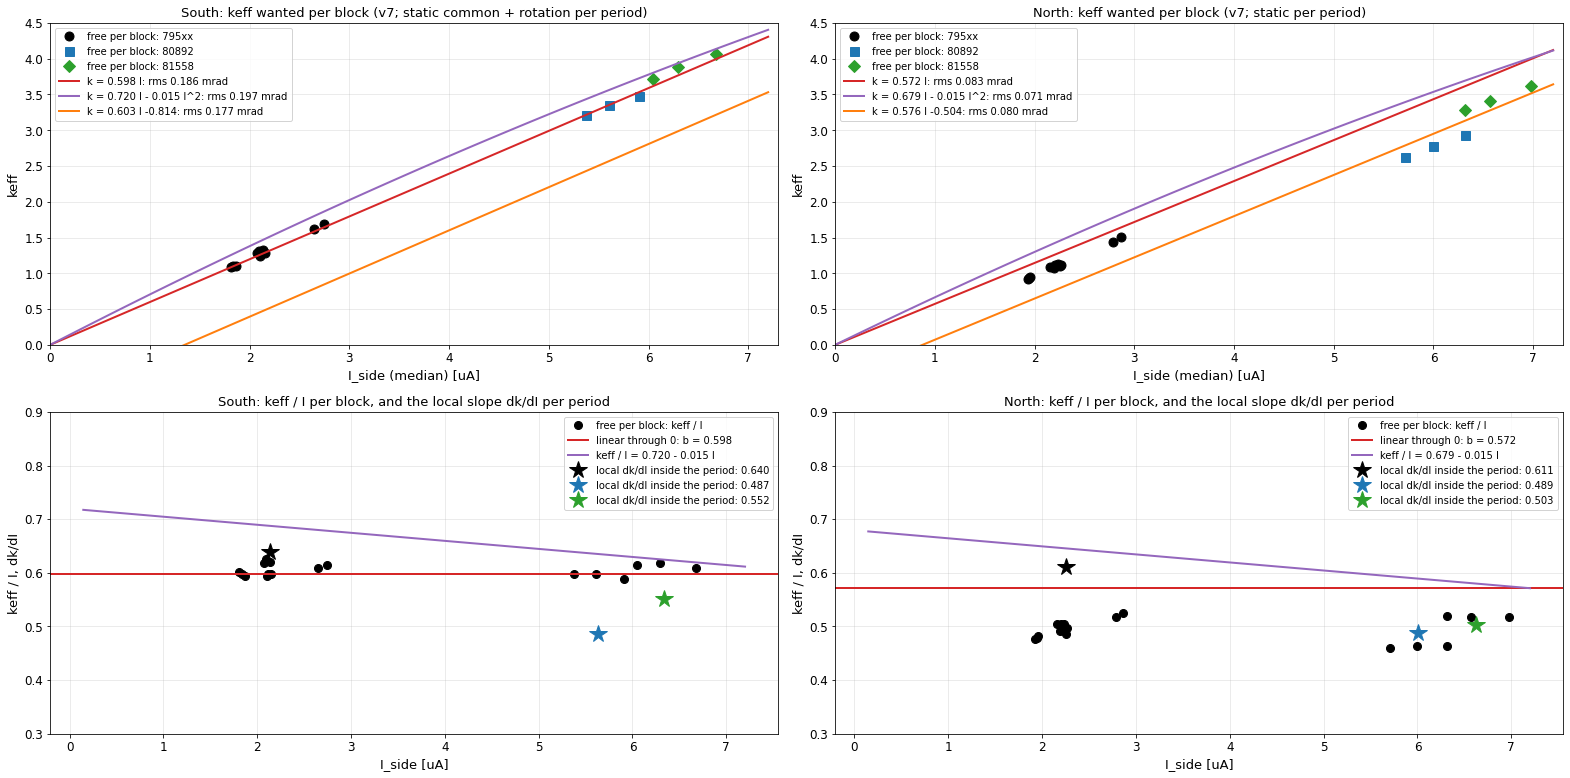

In [3]:
d.SPLIT_SOUTH = False
show(d.fig_keff_blocks('v7'))

### 2b. Static per period on both sides

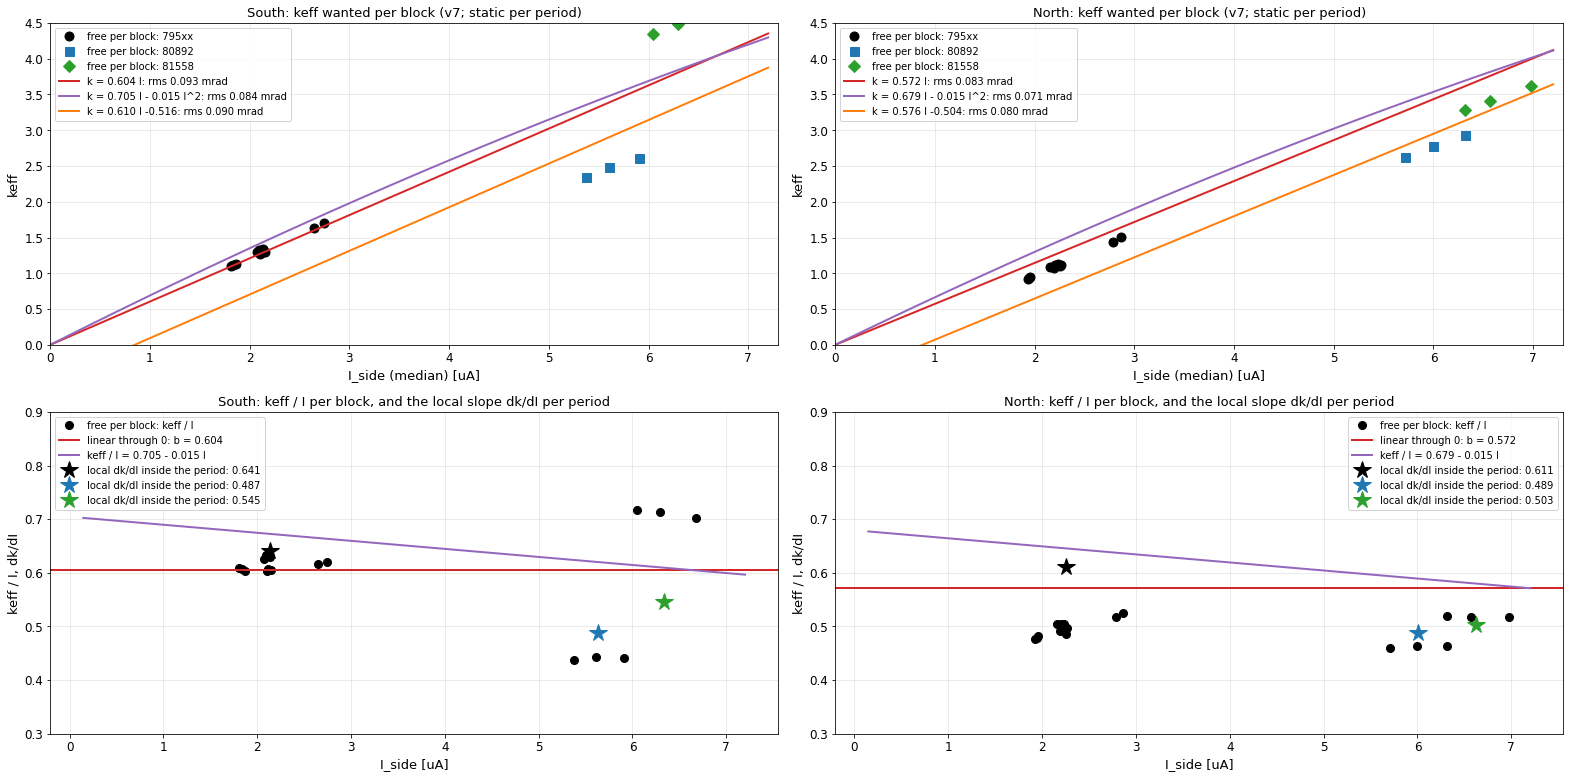

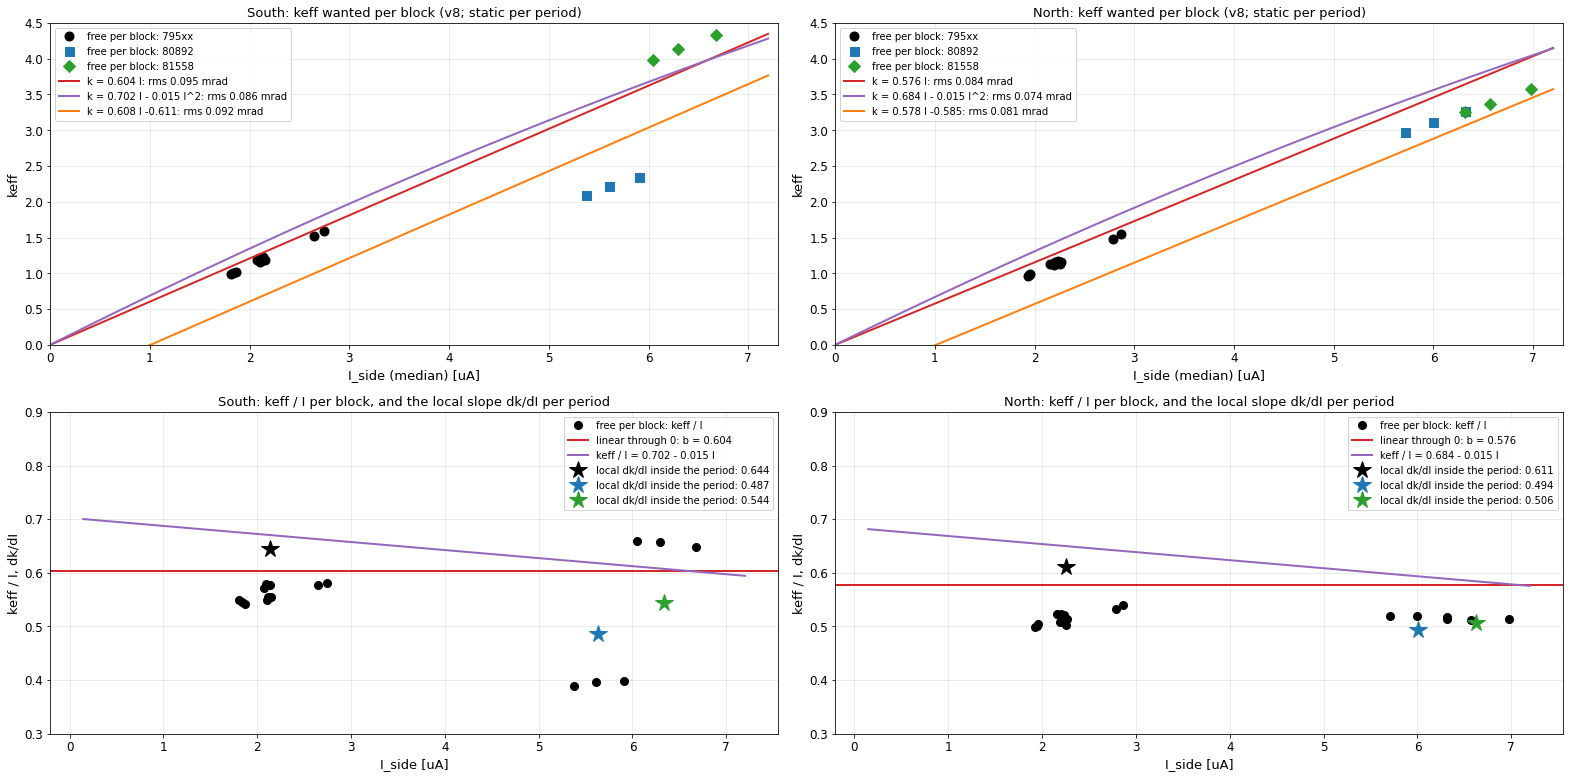

In [4]:
d.SPLIT_SOUTH = True
show(d.fig_keff_blocks('v7'), d.fig_keff_blocks('v8'))

### 2c. How much curvature: keff = a I − c I², c fixed, a fitted (residual rms of all blocks)

In [5]:
for scan in ('v7', 'v8'):
    for split in (False, True):
        d.SPLIT_SOUTH = split
        for s in (0, 1):
            if s == 1 and not split:
                continue
            row = ' | '.join(f"c {cf:.3f}: a {d.fit_keff(s, scan, f'cfix{cf}')['params'][0]:.3f}, rms {d.fit_keff(s, scan, f'cfix{cf}')['rms']:.4f}" for cf in (0, 0.005, 0.01, 0.015, 0.02, 0.03))
            print(f"{scan} {c.SIDES[s]:5s} static {'per period' if (split or s == 1) else 'common'}: {row}")
d.SPLIT_SOUTH = True
for s in (0, 1):
    fr = d.fit_keff(s, 'v7', 'free'); p = d.periods(s)
    print(c.SIDES[s], 'local dk/dI:', ', '.join(f"{nm} {np.polyfit(fr['I'][p == g], fr['k'][p == g], 1)[0]:.3f} (I {fr['I'][p == g].mean():.2f})" for g, nm in ((0, '795xx'), (1, '80892'), (2, '81558'))))

v7 South static common: c 0.000: a 0.598, rms 0.1857 | c 0.005: a 0.639, rms 0.1879 | c 0.010: a 0.679, rms 0.1917 | c 0.015: a 0.720, rms 0.1970 | c 0.020: a 0.760, rms 0.2036 | c 0.030: a 0.841, rms 0.2205
v7 South static per period: c 0.000: a 0.604, rms 0.0926 | c 0.005: a 0.638, rms 0.0877 | c 0.010: a 0.671, rms 0.0847 | c 0.015: a 0.705, rms 0.0839 | c 0.020: a 0.738, rms 0.0852 | c 0.030: a 0.805, rms 0.0939
v7 North static per period: c 0.000: a 0.572, rms 0.0826 | c 0.005: a 0.608, rms 0.0762 | c 0.010: a 0.644, rms 0.0722 | c 0.015: a 0.679, rms 0.0712 | c 0.020: a 0.715, rms 0.0732 | c 0.030: a 0.786, rms 0.0851
v8 South static common: c 0.000: a 0.598, rms 0.1872 | c 0.005: a 0.638, rms 0.1897 | c 0.010: a 0.679, rms 0.1939 | c 0.015: a 0.719, rms 0.1996 | c 0.020: a 0.760, rms 0.2068 | c 0.030: a 0.841, rms 0.2248
v8 South static per period: c 0.000: a 0.604, rms 0.0948 | c 0.005: a 0.637, rms 0.0899 | c 0.010: a 0.670, rms 0.0868 | c 0.015: a 0.702, rms 0.0858 | c 0.020:

- With the static per period, both sides and both scans prefer **c ≈ 0.015 µA⁻¹** (a ≈ 0.70 S, 0.68 N): keff / I falls
  from 0.67 at 2 µA to 0.61 at 6 µA, and the local slope from 0.64 to 0.52.
- With one common South static, c = 0 is preferred – but that fit is 2× worse (0.186 vs 0.093 mrad): the South static
  does change between the periods (Section 4), and a common static forces the cross-period chord on keff.
- **Applying it per block and per run**: keff_j = a I_j − 0.015 I_j² with I_j the block's median GEM current; at 795xx
  this is ≈ 11 % more than 0.60 I, at 6 µA ≈ 2 % more – the static re-fit (Section 6) absorbs the change.

### 2d. Where in R the non-linearity is (no map): P_j = S_p(R) + I A(R) + I² B(R)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:238: RuntimeWarning: Mean of empty slice
  U = np.nanmean(unit_response(s, scan)[1], axis=0); lin = fit_keff(s, scan, 'lin0')['params'][0]


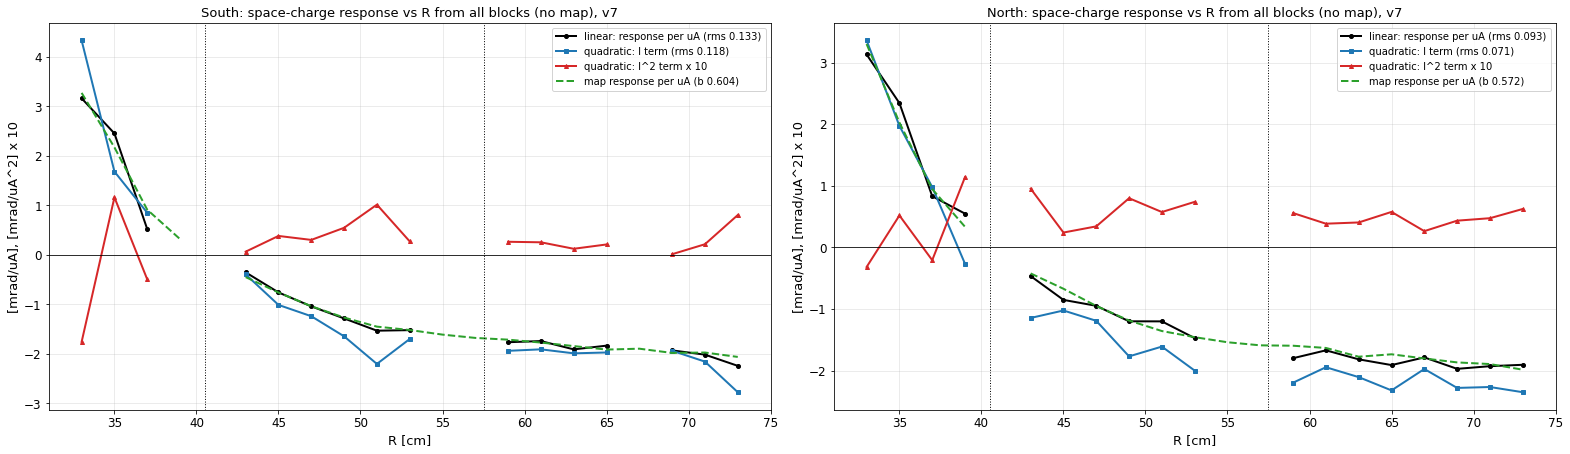

In [6]:
show(d.fig_free_shape('v7'))

In [7]:
for s in (0, 1):
    A, B, r = d.free_shape(s, 'v7', 2)
    for lo, hi, nm in ((32, 40.5, 'R1'), (42, 57.5, 'R2'), (57.5, 76, 'R3')):
        m = (d.R > lo) & (d.R < hi) & np.isfinite(A)
        a, b = np.mean(A[m]), np.mean(B[m])
        print(f"{c.SIDES[s]} {nm}: response per uA at 2 uA {a + 4 * b:+.3f}, at 6 uA {a + 12 * b:+.3f} mrad/uA -> ratio {(a + 12 * b) / (a + 4 * b):.2f}")

South R1: response per uA at 2 uA +2.139, at 6 uA +1.846 mrad/uA -> ratio 0.86
South R2: response per uA at 2 uA -1.197, at 6 uA -0.855 mrad/uA -> ratio 0.71
South R3: response per uA at 2 uA -1.992, at 6 uA -1.779 mrad/uA -> ratio 0.89
North R1: response per uA at 2 uA +1.624, at 6 uA +1.851 mrad/uA -> ratio 1.14
North R2: response per uA at 2 uA -1.214, at 6 uA -0.728 mrad/uA -> ratio 0.60
North R3: response per uA at 2 uA -1.994, at 6 uA -1.623 mrad/uA -> ratio 0.81


The response per µA is weaker at 6 µA in R2 / R3 (ratio 0.60–0.89); in R1 it is mixed (South 0.86, North 1.14) –
R1 changes shape with the current, not only its scale (the kink / inner density moving with I).

## 3. Which map (global fit, each map's own response shape)

In [8]:
for scan in ('v7', 'v8'):
    for s in (0, 1):
        for row in d.map_ranking(s, scan):
            print(f"{scan} {c.SIDES[s]:5s} {q.mlab(row[0]):28s} " + ' | '.join(f"{lab}: rms {x[0]:.4f}, a {x[1]:.3f}" for lab, x in zip(('keff = a I', 'keff = a I - 0.015 I^2'), row[1:])))

v7 South alpha 1.8 kink 22.75         keff = a I: rms 0.0985, a 0.636 | keff = a I - 0.015 I^2: rms 0.0941, a 0.736
v7 South alpha 1.8 kink 23.90         keff = a I: rms 0.0941, a 0.623 | keff = a I - 0.015 I^2: rms 0.0882, a 0.722
v7 South alpha 1.8 kink 25.00         keff = a I: rms 0.0942, a 0.607 | keff = a I - 0.015 I^2: rms 0.0870, a 0.707
v7 South alpha 1.8 kink 26.25         keff = a I: rms 0.0944, a 0.577 | keff = a I - 0.015 I^2: rms 0.0848, a 0.677
v7 South alpha 1.8 kink 27.50         keff = a I: rms 0.0993, a 0.550 | keff = a I - 0.015 I^2: rms 0.0924, a 0.650
v7 South alpha 1.6 kink 23.90         keff = a I: rms 0.0945, a 0.613 | keff = a I - 0.015 I^2: rms 0.0868, a 0.713
v7 South alpha 1.6 kink 25.00         keff = a I: rms 0.0932, a 0.603 | keff = a I - 0.015 I^2: rms 0.0853, a 0.703
v7 South alpha 1.6 kink 26.25         keff = a I: rms 0.0974, a 0.573 | keff = a I - 0.015 I^2: rms 0.0895, a 0.673
v7 South alpha 1.7 kink 25.00         keff = a I: rms 0.0926, a 0.604 | 

v7 North alpha 1.8 kink 22.75         keff = a I: rms 0.0924, a 0.609 | keff = a I - 0.015 I^2: rms 0.0831, a 0.716
v7 North alpha 1.8 kink 23.90         keff = a I: rms 0.0882, a 0.591 | keff = a I - 0.015 I^2: rms 0.0783, a 0.698
v7 North alpha 1.8 kink 25.00         keff = a I: rms 0.0871, a 0.575 | keff = a I - 0.015 I^2: rms 0.0757, a 0.682
v7 North alpha 1.8 kink 26.25         keff = a I: rms 0.0805, a 0.553 | keff = a I - 0.015 I^2: rms 0.0729, a 0.659
v7 North alpha 1.8 kink 27.50         keff = a I: rms 0.0837, a 0.526 | keff = a I - 0.015 I^2: rms 0.0749, a 0.632
v7 North alpha 1.6 kink 23.90         keff = a I: rms 0.0829, a 0.582 | keff = a I - 0.015 I^2: rms 0.0730, a 0.689
v7 North alpha 1.6 kink 25.00         keff = a I: rms 0.0824, a 0.570 | keff = a I - 0.015 I^2: rms 0.0736, a 0.676
v7 North alpha 1.6 kink 26.25         keff = a I: rms 0.0849, a 0.546 | keff = a I - 0.015 I^2: rms 0.0785, a 0.652
v7 North alpha 1.7 kink 25.00         keff = a I: rms 0.0842, a 0.572 | 

v8 South alpha 1.6 kink 25.00         keff = a I: rms 0.0966, a 0.600 | keff = a I - 0.015 I^2: rms 0.0878, a 0.699
v8 South alpha 1.6 kink 26.25         keff = a I: rms 0.1003, a 0.575 | keff = a I - 0.015 I^2: rms 0.0920, a 0.674
v8 South alpha 1.7 kink 25.00         keff = a I: rms 0.0948, a 0.604 | keff = a I - 0.015 I^2: rms 0.0858, a 0.702
v8 South alpha 1.8 kink 22.75         keff = a I: rms 0.1012, a 0.637 | keff = a I - 0.015 I^2: rms 0.0946, a 0.735


v8 North alpha 1.6 kink 25.00         keff = a I: rms 0.0852, a 0.574 | keff = a I - 0.015 I^2: rms 0.0745, a 0.681
v8 North alpha 1.6 kink 26.25         keff = a I: rms 0.0874, a 0.548 | keff = a I - 0.015 I^2: rms 0.0805, a 0.655
v8 North alpha 1.7 kink 25.00         keff = a I: rms 0.0861, a 0.576 | keff = a I - 0.015 I^2: rms 0.0749, a 0.684
v8 North alpha 1.8 kink 22.75         keff = a I: rms 0.0918, a 0.611 | keff = a I - 0.015 I^2: rms 0.0826, a 0.718


- South: α 1.7 kink 25 (0.084) ≈ α 1.6 kink 25 (0.085) ≈ α 1.8 kink 26.25 (0.085); North: α 1.8 kink 26.25 / α 1.6 kink
  23.9–25 (0.073). α 1.8 kink 22.75 (the CDB shape) is worst on both sides. The differences are ≤ 0.01 mrad: the
  CM does not resolve the profile further; the curvature in I gains more than any map change.
- v8 (on the new static) gives the same ranking: the space charge is independent of the static.

## 4. The static changes between periods
The static per period from the fit (Section 2b), 80892 − 795xx and 81558 − 795xx, with the frame-charge response (and IFC /
OFC) fitted to it.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/static7.py:53: RuntimeWarning: Mean of empty slice
  P = np.nanmean(P, axis=0) if P else np.full(len(R), np.nan)


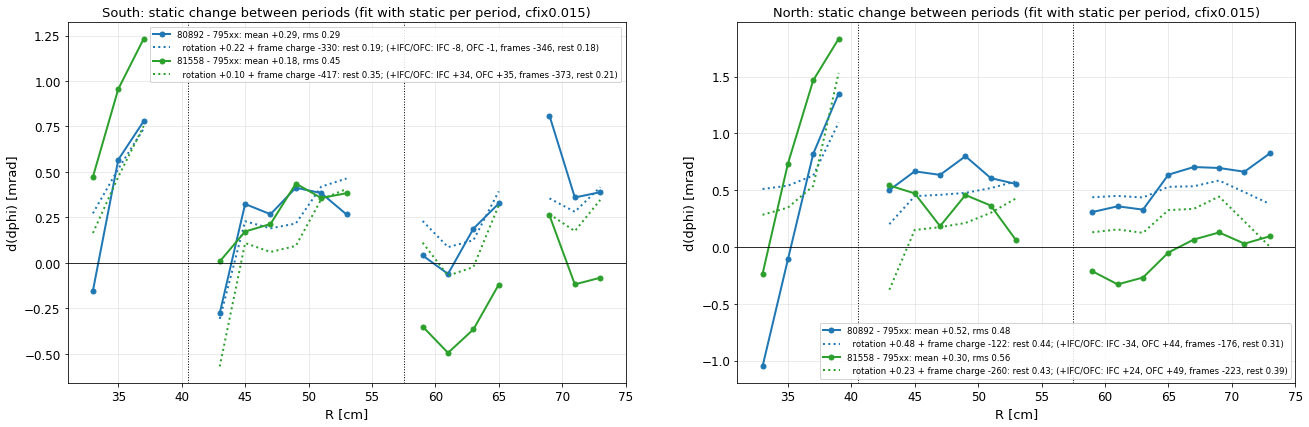

In [9]:
show(d.fig_period_static('v7'))

The change is mostly a rotation (+0.3 S, +2–3 mrad N including the North static jump) with a shape the frame charge alone
does not describe; IFC / OFC / frames together fit it only with large values – the static moves in time (Section 6).

## 5. 3D: the space-charge scale per pad module
Per sector (30°, edges excluded) and 4-cm R bin: g = data scale / map scale with keff_j from the φ-integrated fit
(keff = a I − 0.015 I², static per period per bin). Errors: jackknife over the six runs.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:331: RuntimeWarning: Mean of empty slice
  err = np.sqrt((n - 1) / n * np.nansum((J - np.nanmean(J, axis=0)) ** 2, axis=0))
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:346: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES0, axis=0), 'k-o', label='phi-integrated keff only (g = 1)')
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:347: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES, axis=0), 'b-s', label='with g per sector x R')


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:346: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES0, axis=0), 'k-o', label='phi-integrated keff only (g = 1)')
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:347: RuntimeWarning: All-NaN slice encountered
  axs[s, 2].plot(R4, np.nanmedian(RES, axis=0), 'b-s', label='with g per sector x R')


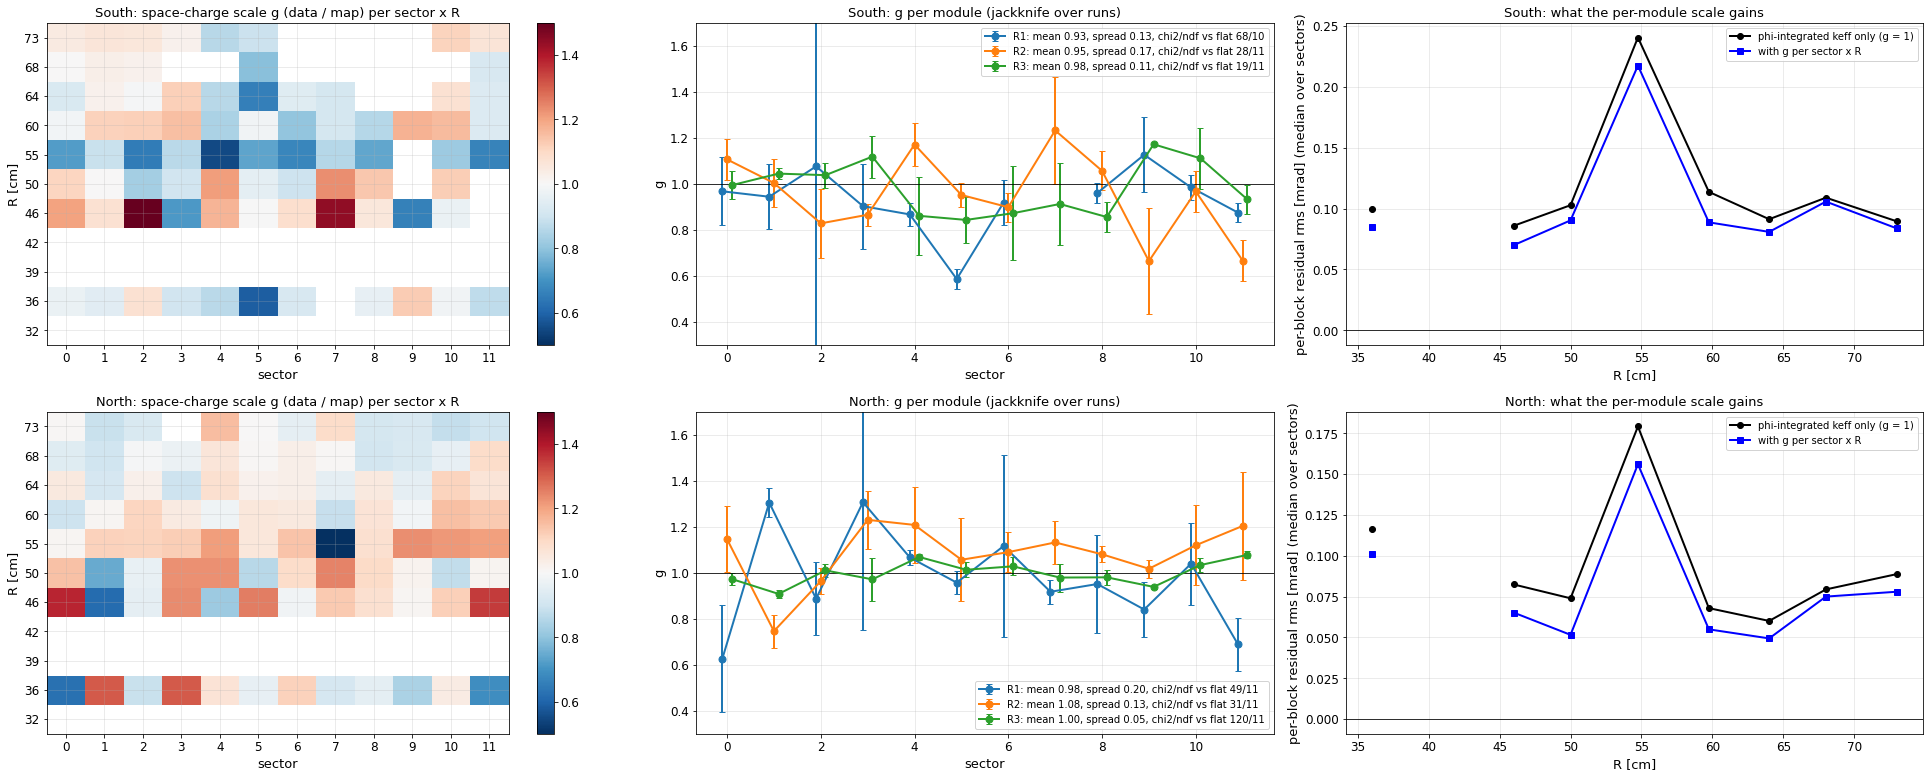

In [10]:
show(d.fig_gain_err('v7'))

In [11]:
for s in (0, 1):
    MG, err, G, RES, RES0 = d.gain_jackknife(s, 'v7', 'cfix0.015')
    for j, nm in enumerate(('R1', 'R2', 'R3')):
        print(f"{c.SIDES[s]} {nm}: " + ' '.join(f"{x:.2f}+-{e:.2f}" for x, e in zip(MG[:, j], err[:, j])))

South R1: 0.97+-0.15 0.94+-0.14 1.08+-0.95 0.90+-0.18 0.87+-0.05 0.59+-0.04 0.92+-0.10 nan+-0.00 0.96+-0.04 1.13+-0.16 0.98+-0.05 0.87+-0.04
South R2: 1.11+-0.09 1.00+-0.10 0.83+-0.15 0.87+-0.05 1.17+-0.10 0.95+-0.05 0.90+-0.06 1.23+-0.23 1.06+-0.08 0.66+-0.23 0.97+-0.09 0.67+-0.09
South R3: 0.99+-0.06 1.04+-0.02 1.04+-0.05 1.12+-0.09 0.86+-0.17 0.84+-0.10 0.87+-0.20 0.91+-0.18 0.86+-0.07 1.17+-0.00 1.11+-0.13 0.93+-0.06
North R1: 0.63+-0.23 1.31+-0.06 0.89+-0.16 1.31+-0.56 1.07+-0.03 0.96+-0.05 1.12+-0.40 0.92+-0.05 0.95+-0.21 0.84+-0.12 1.04+-0.18 0.69+-0.12
North R2: 1.15+-0.14 0.75+-0.07 0.96+-0.06 1.23+-0.13 1.21+-0.17 1.06+-0.18 1.09+-0.09 1.13+-0.09 1.08+-0.04 1.02+-0.04 1.12+-0.17 1.20+-0.23
North R3: 0.97+-0.03 0.91+-0.02 1.01+-0.03 0.97+-0.09 1.07+-0.01 1.01+-0.03 1.03+-0.04 0.98+-0.06 0.98+-0.03 0.94+-0.01 1.03+-0.03 1.08+-0.01


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:331: RuntimeWarning: Mean of empty slice
  err = np.sqrt((n - 1) / n * np.nansum((J - np.nanmean(J, axis=0)) ** 2, axis=0))


### Per sector: the measured response per µA vs the map

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/sc3d.py:316: RuntimeWarning: Mean of empty slice
  axs[i].plot(R4, lin * np.nanmean(U[:, i], axis=0), '--', color='tab:green', lw=2, label=f'map x b {lin:.2f}')


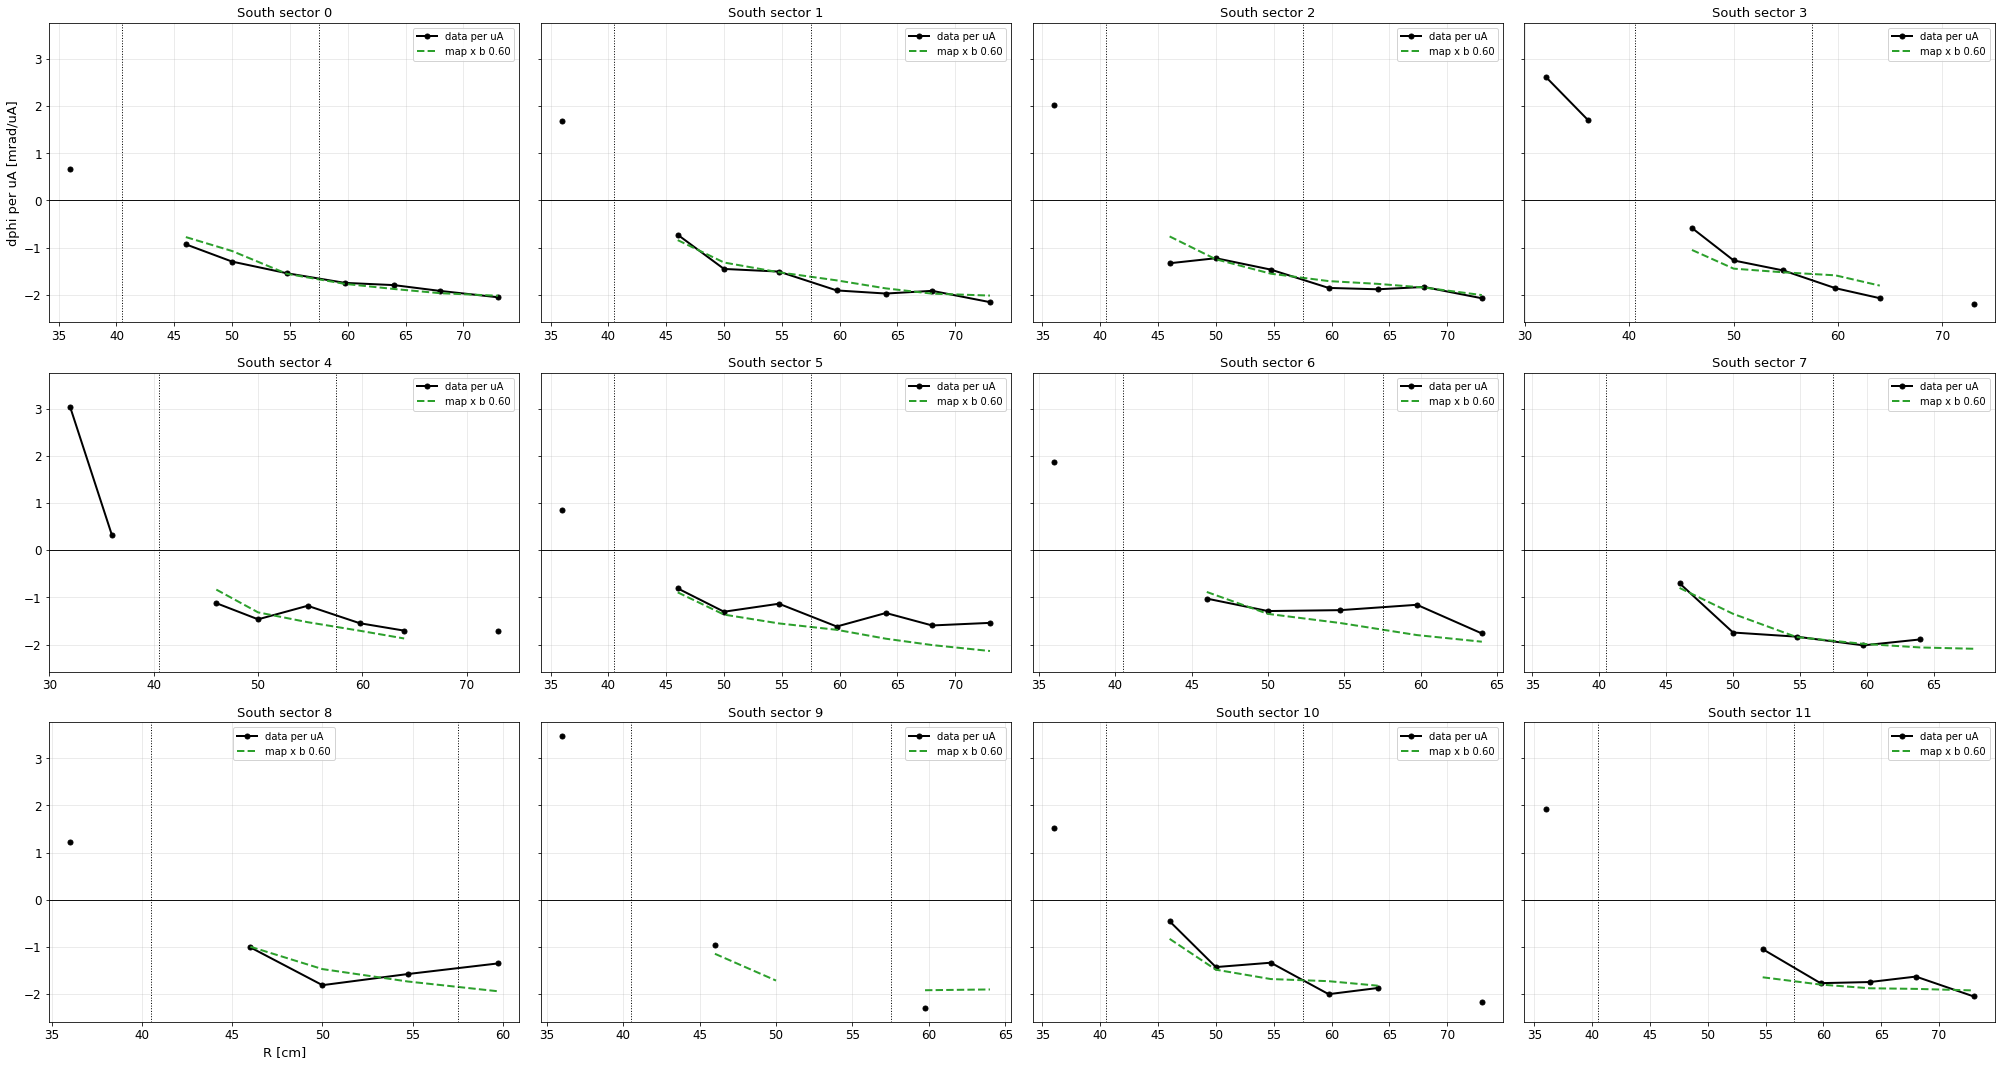

In [12]:
show(d.fig_sector_response(0, 'v7'))

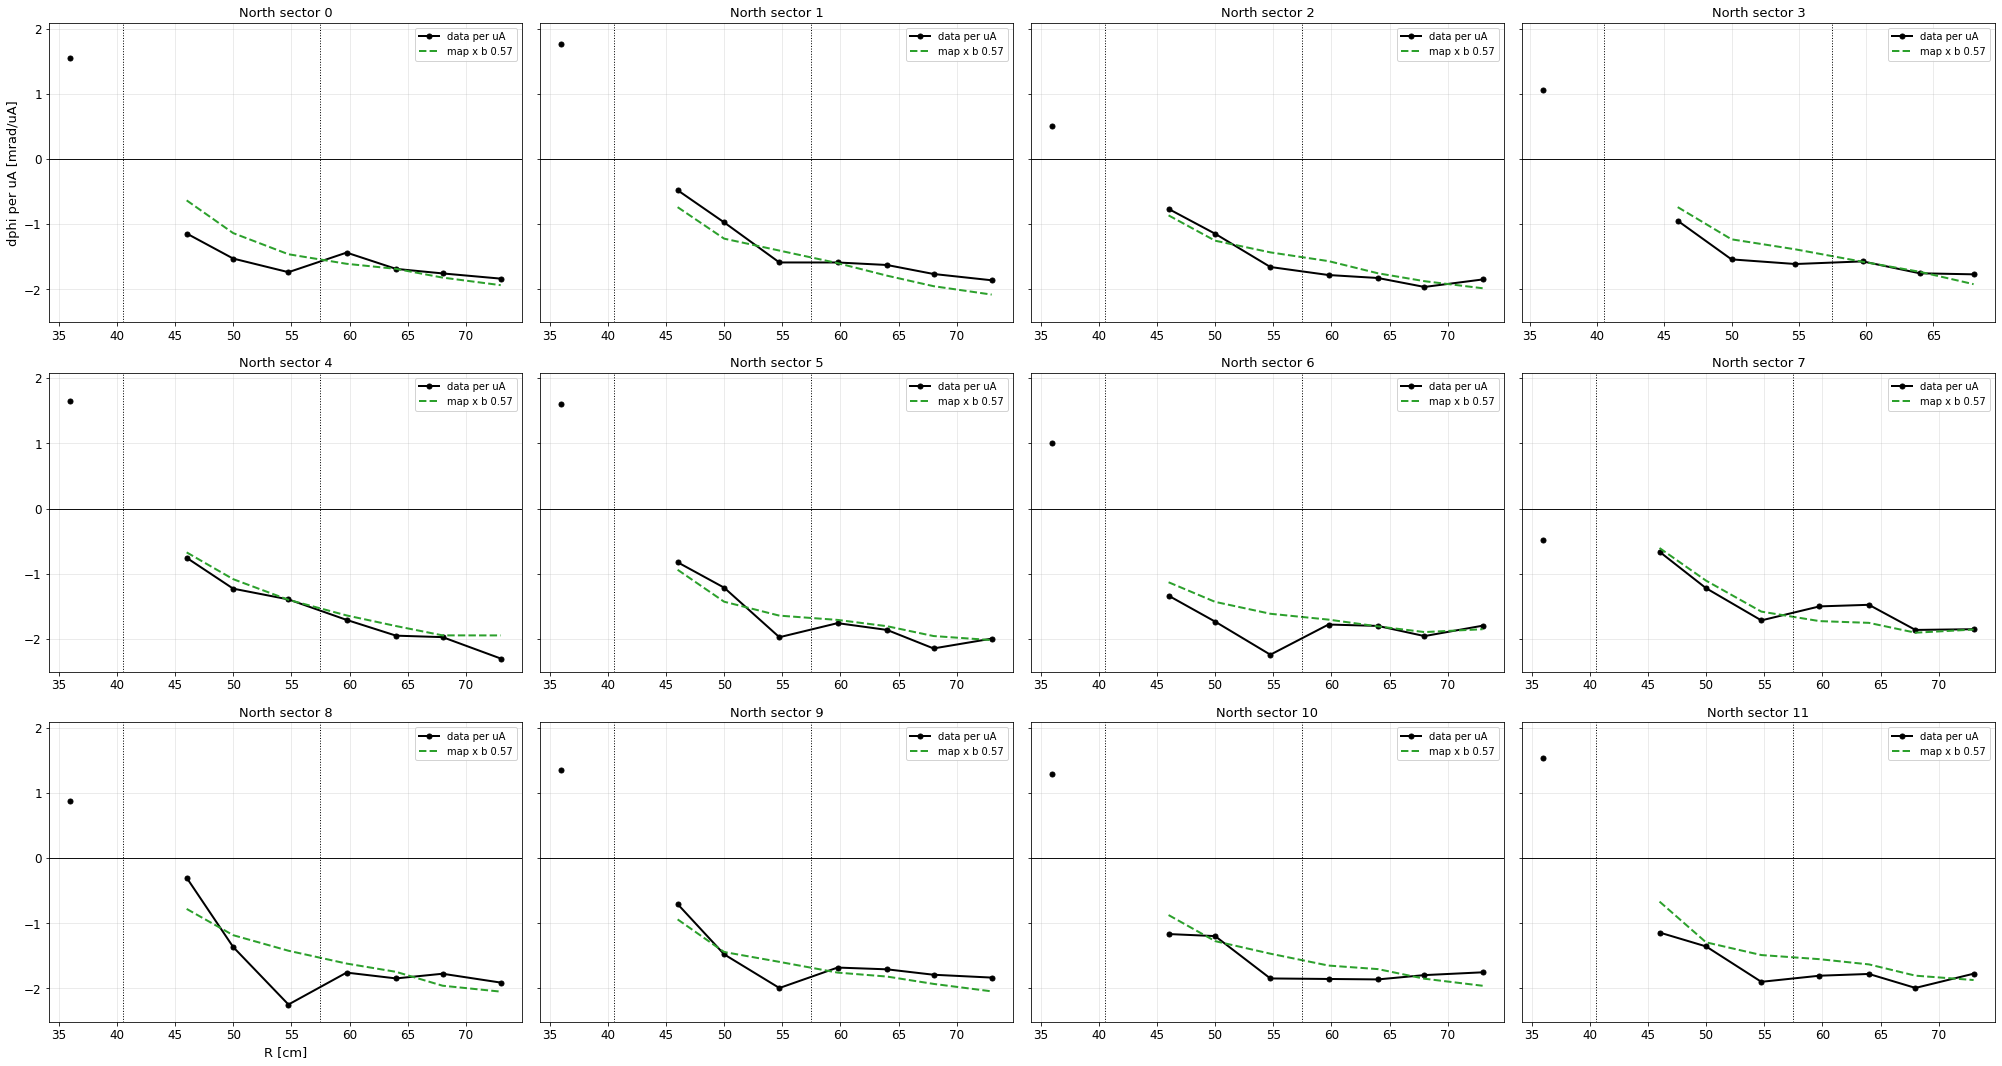

In [13]:
show(d.fig_sector_response(1, 'v7'))

- North R3 is uniform (g spread 0.05, errors 0.01–0.06); R1 and R2 vary by 0.13–0.2 between sectors. Significant outliers
  (jackknife): South R1 sector 5 0.59 ± 0.04, South R2 sector 11 0.67 ± 0.09, North R1 sector 1 1.31 ± 0.06, North R2
  sector 1 0.75 ± 0.07; others (North R1 sectors 0 / 3 / 6) have errors 0.2–0.6 – per-module GEM gain × IBF.
- With g per module the per-block residual drops ≈ 15 % (0.09 → 0.08 mrad): worth including in the density map (per-module
  weights) once the errors confirm the outliers; it is not what limits the φ-integrated correction.

## 6. The static per period on v8, with keff = a I − 0.015 I²
Knob responses per period (per +20 V IFC / OFC, +30 frame charge, +1 in R1 frame weight):

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cal8.py:74: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0)


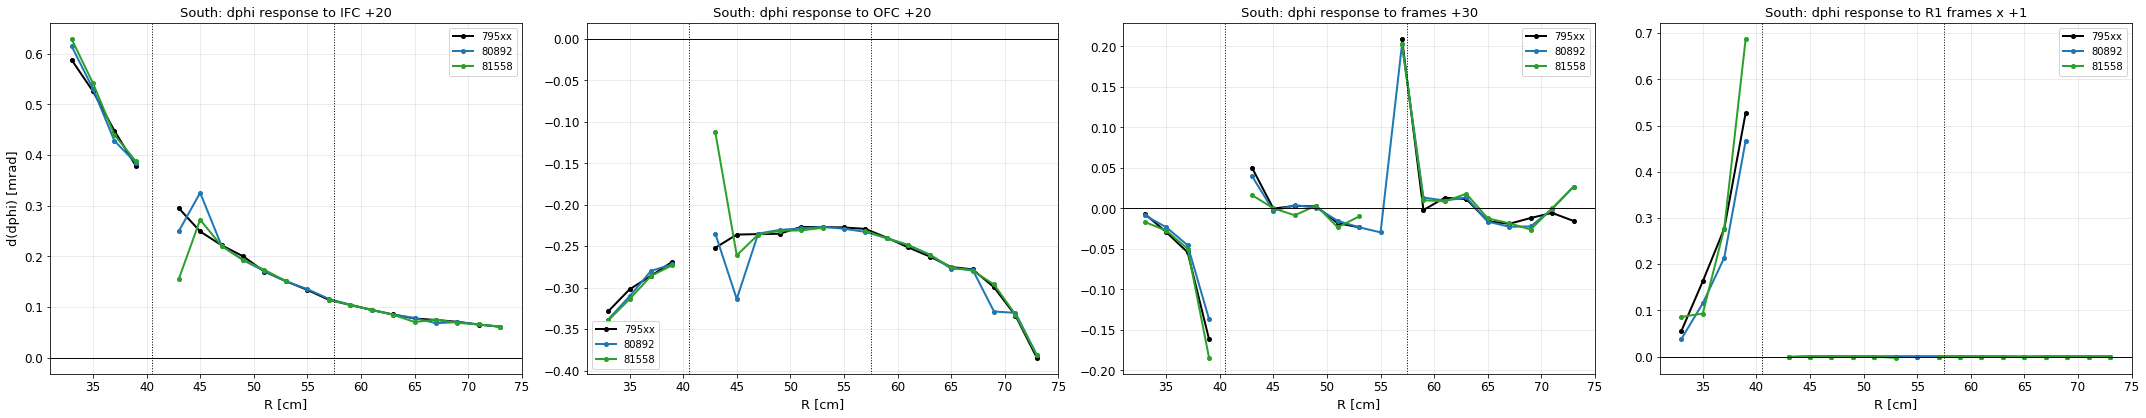

In [14]:
show(k8.fig_responses(0))

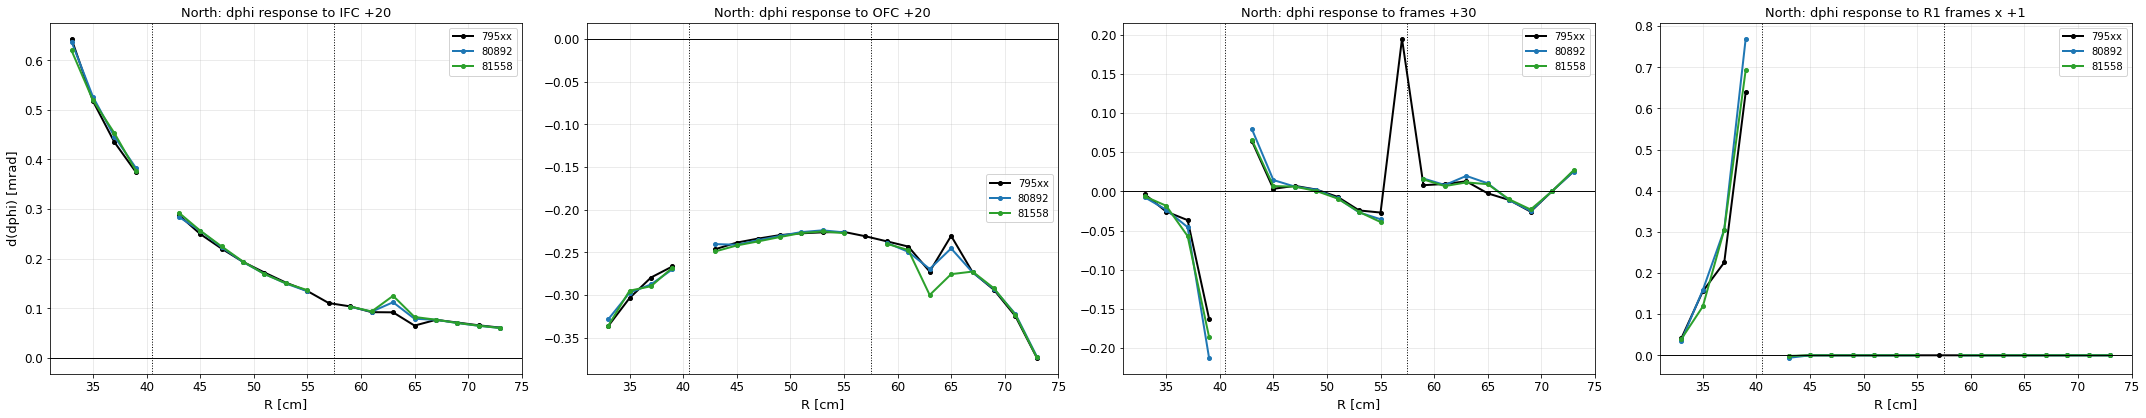

In [15]:
show(k8.fig_responses(1))

Fits: IFC, OFC, frame charge per period (joint objective: dφ flat, R² / pointing / shift on target, flat steps, small
changes). 795xx with all bins (K0s-calibrated R² = 0); every period also with R > 32 cm, whose R² / pointing targets
are the values of the 795xx all-bin solution in that metric. Also: frames only; and with the R1 frame weight.

In [16]:
for s in (0, 1):
    for knobs in (('IFC', 'OFC', 'frames'), ('frames',), ('IFC', 'OFC', 'frames', 'R1 frames x')):
        tg, sols = k8.solutions(s, knobs=knobs)
        print(f"{c.SIDES[s]} knobs {knobs}: targets (R > 32 metric) R2 {tg['R2']:+.0f} um, pointing {tg['pointing']:+.2f}, shift {tg['shift']:+.2f}")
        for lab, o in sols:
            dd = o['d']; ab = lambda n, b: f"{b + dd[n]:+5.0f}" if n in dd else '    -'
            print(f"   {lab:30s} IFC {ab('IFC', k8.BASE['ifc'][s])} OFC {ab('OFC', k8.BASE['ofc'][s])} frames {ab('frames', k8.BASE['frame'][s])}" + (f" R1 x{1 + dd['R1 frames x']:.2f}" if 'R1 frames x' in dd else '') + ' | ' + qline(o['Q']))
    for nm, runs in k8.PER:
        Cp, Cr = k8.cdb_period(s, runs); print(f"   CDB {nm:26s} " + qline(k8.quantities(Cp, Cr)))
    print()

South knobs ('IFC', 'OFC', 'frames'): targets (R > 32 metric) R2 +221 um, pointing +1.33, shift +0.34
   795xx (all bins, K0s metric)   IFC    -4 OFC    +4 frames  -157 | dphi rms 0.46, shift -0.01 mm, R2    +1 um, pt +0.03 mm, steps +0.02/-0.02 mm, R1 arch +0.58
   795xx (R > 32)                 IFC   -17 OFC    -4 frames  -163 | dphi rms 0.31, shift +0.14 mm, R2  +228 um, pt +1.16 mm, steps -0.01/+0.01 mm, R1 arch +0.52
   80892 (R > 32)                 IFC   -26 OFC   +14 frames  -108 | dphi rms 0.44, shift +0.09 mm, R2  +232 um, pt +1.15 mm, steps -0.51/-0.40 mm, R1 arch +0.69
   81558 (R > 32)                 IFC   -66 OFC    +7 frames  -149 | dphi rms 0.45, shift +0.18 mm, R2  +137 um, pt +0.83 mm, steps -0.56/-0.34 mm, R1 arch +0.54
South knobs ('frames',): targets (R > 32 metric) R2 +101 um, pointing +0.11, shift -0.34
   795xx (all bins, K0s metric)   IFC     - OFC     - frames  -207 | dphi rms 0.67, shift -0.77 mm, R2  -149 um, pt -1.37 mm, steps -0.17/+0.19 mm, R1 arch +0.22

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/cal8.py:173: RuntimeWarning: Mean of empty slice
  Pp = np.nanmean([bp('cdb', r, k, s, 5) for r, k, I in blocks(runs)], axis=0); Pr = np.nanmean([bp('cdb', r, k, s, 4) for r, k, I in blocks(runs)], axis=0)


   CDB 795xx                      dphi rms 0.56, shift +0.86 mm, R2  +202 um, pt +1.79 mm, steps -0.17/+0.28 mm, R1 arch +0.73


   CDB 80892                      dphi rms 0.73, shift +0.38 mm, R2   -12 um, pt +0.38 mm, steps -1.10/+0.10 mm, R1 arch +0.39


   CDB 81558                      dphi rms 1.19, shift +1.78 mm, R2  +206 um, pt +2.75 mm, steps -1.23/-0.03 mm, R1 arch +1.16

North knobs ('IFC', 'OFC', 'frames'): targets (R > 32 metric) R2 +85 um, pointing +0.53, shift +0.15
   795xx (all bins, K0s metric)   IFC   -43 OFC    -6 frames  -182 | dphi rms 0.25, shift +0.01 mm, R2    -6 um, pt -0.01 mm, steps -0.19/-0.21 mm, R1 arch +0.25
   795xx (R > 32)                 IFC   -48 OFC    -9 frames  -185 | dphi rms 0.21, shift +0.07 mm, R2   +82 um, pt +0.43 mm, steps -0.20/-0.20 mm, R1 arch +0.22
   80892 (R > 32)                 IFC   -11 OFC    -9 frames   -27 | dphi rms 0.37, shift +0.07 mm, R2   +82 um, pt +0.52 mm, steps -0.04/+0.14 mm, R1 arch -0.20
   81558 (R > 32)                 IFC   -70 OFC    -5 frames    -9 | dphi rms 0.44, shift +0.08 mm, R2   +88 um, pt +0.53 mm, steps -0.03/+0.11 mm, R1 arch -0.07
North knobs ('frames',): targets (R > 32 metric) R2 -174 um, pointing -1.70, shift -0.91
   795xx (all bins, K0s metric)   

   CDB 795xx                      dphi rms 0.81, shift +1.61 mm, R2  +148 um, pt +2.29 mm, steps -0.31/-0.13 mm, R1 arch +0.78


   CDB 80892                      dphi rms 1.20, shift +1.49 mm, R2  -265 um, pt +0.43 mm, steps -1.15/-0.70 mm, R1 arch -0.14


   CDB 81558                      dphi rms 1.72, shift +3.08 mm, R2   +66 um, pt +3.49 mm, steps -1.13/-0.51 mm, R1 arch +1.06



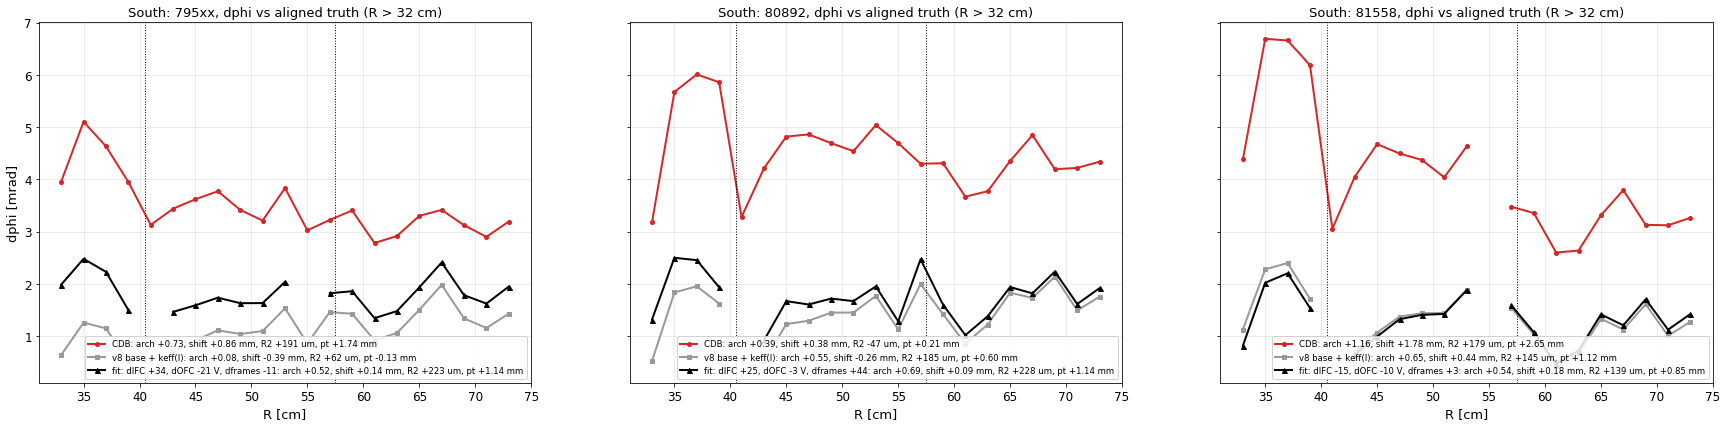

In [17]:
show(k8.fig_solutions(0))

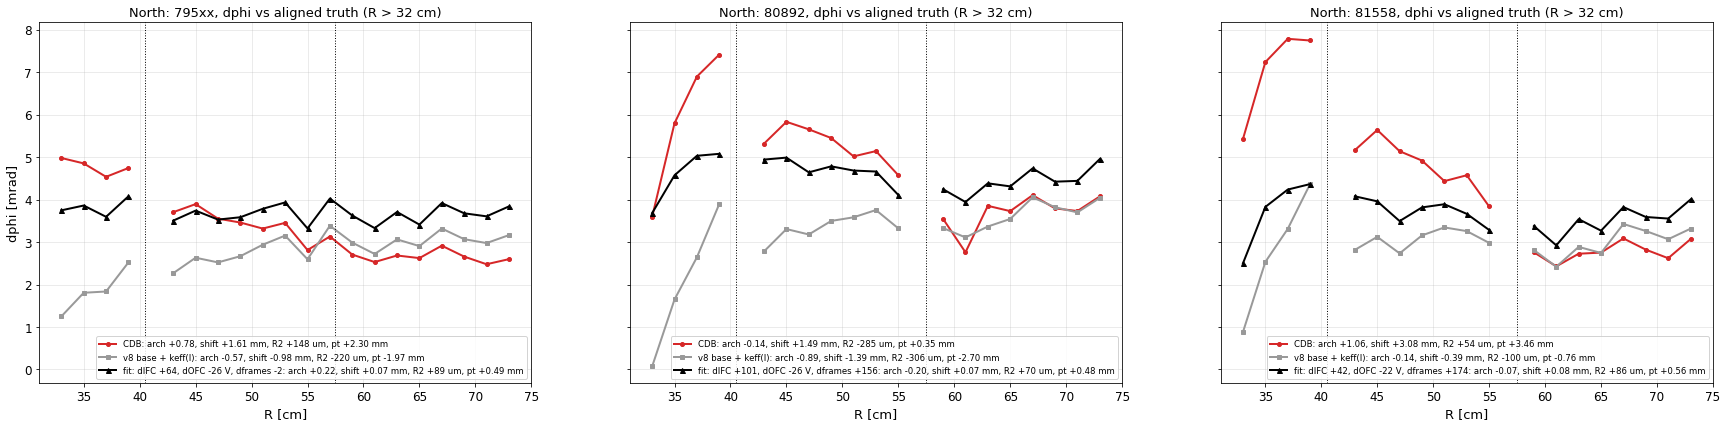

In [18]:
show(k8.fig_solutions(1))

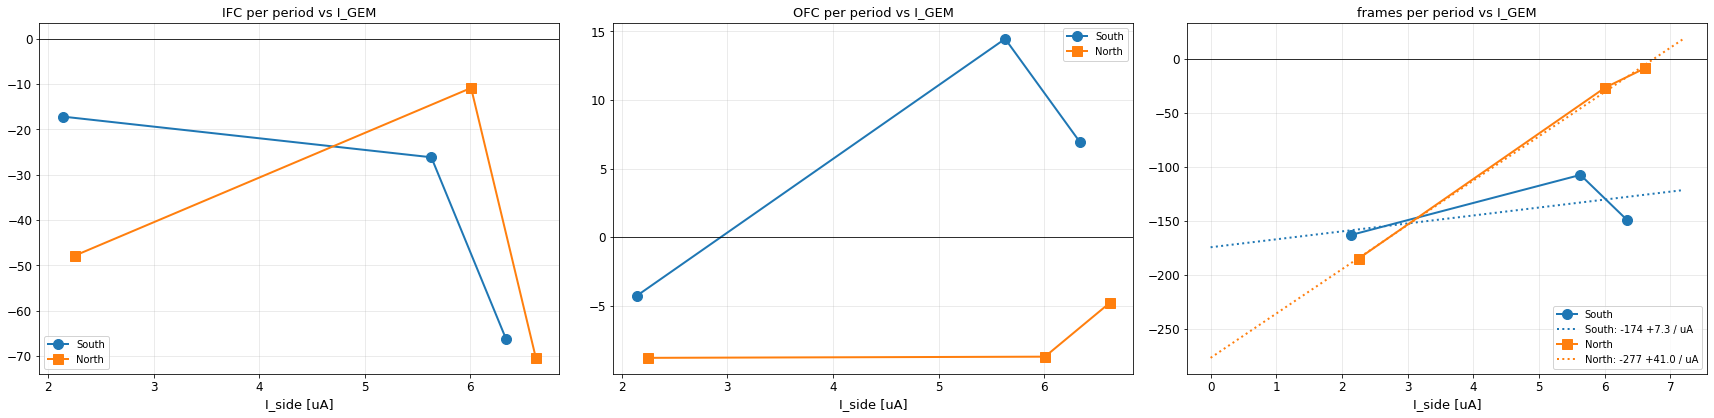

In [19]:
show(k8.fig_frames_vs_I())

**795xx static (K0s metric)**:

| | IFC | OFC | frames | dφ rms (CDB) | shift (CDB) | R² (CDB) | pointing (CDB) | steps | R1 arch (CDB) |
|---|---|---|---|---|---|---|---|---|---|
| South | −4 V | +4 V | −157 | 0.46 (0.56) | −0.01 (0.86) mm | +1 (+202*) µm | 0.03 (1.79*) mm | +0.02 / −0.02 | +0.58 (+0.73) |
| North | −43 V | −6 V | −182 | 0.25 (0.81) | +0.01 (1.61) mm | −6 (+148*) µm | −0.01 (2.29*) mm | −0.19 / −0.21 | +0.25 (+0.78) |

(* CDB in the R > 32 metric; in the K0s metric the CDB R² is −31 / +50 µm.)

- **Small voltages on both sides**, frames −157 / −182. The North IFC is no longer −112 … −138 V: that was compensating
  the too-small keff at 795xx (0.55–0.60 I instead of 0.68–0.70 I − 0.015 I²).
- **Per period**: the knobs scatter (IFC −17 / −26 / −66 S, −48 / −11 / −70 N; frames −163 / −108 / −149 S, −185 / −27 / −9 N):
  no trend with the current; 80892 and 81558 (same current) differ → **the static is time dependent**, not beam
  dependent. For the K0s runs (795xx) the 795xx static is the one to use.
- **8xxxx South steps −0.4 … −0.56 mm** remain (0 at 795xx; CDB −1.1 mm): they scale with the current → space-charge
  map at the module boundaries (density map gaps), not static.
- The **R1 frame weight** does not fix the South R1 arch and runs away at 8xxxx: dropped.

## 8. P/T and the drift velocity: can they explain what is left?
**What our jobs already do.** Every block runs with `cmv=pt@<f>`: the CM drift field E_eff = 376.85 V/cm × (P_ref/P)(T/T_ref)
from TPC_CONDITIONS at the block time (reference 79513), the effective-field prescription of the drift-velocity talks.
**What it does not do**: it scales only the drift field. A density change scales E/N of *every* field component – the
space-charge field and the field-cage and frame perturbations too – so the field *directions* stay the same and only the
mobility (ωτ = μB, the E×B part) changes. Scaling only E_z changes E_r/E_z by the same fraction: the transverse
drift-velocity components are not scaled together with the longitudinal one, as they should be. The right emulation is
to scale the whole field (or the gas table) by the P/T factor.

**Size.** E_eff per run vs 79513 (from the job logs) and the measured drift time t_CM − t0 (raw-time edges, t0 follow-up
talk); d ln v / d ln E ≈ 0.7 from the PHGarfield P/T scan:

In [20]:
E = {'79508': 377.44, '79513': 376.88, '79516': 376.53, '79529': 375.08, '80892': 378.21, '81558': 377.21}
tS = {'79513': 251.05 - 8.40, '79516': 251.51 - 8.39, '79529': 253.18 - 8.36, '80892': 251.27 - 8.58, '81558': 250.62 - 8.67}
tN = {'79513': 251.63 - 8.46, '79516': 252.08 - 8.49, '79529': 253.70 - 8.40, '80892': 251.49 - 8.65, '81558': 251.11 - 8.78}
d.SPLIT_SOUTH = False
fr = d.fit_keff(0, 'v7', 'free'); runs = [r for r, k, a, b in d.blocks()]
kI = {r: np.mean([k / i for rr, k, i in zip(runs, fr['k'], fr['I']) if rr == r]) for r in d.RUNS}
k0 = np.mean([kI['79513'], kI['79516']])
print(f"{'run':8s} {'E_eff vs 79513':>14s} {'P/T: drift time':>16s} {'measured S / N':>18s} {'not P/T S / N':>16s} {'keff/I (S) vs 795xx':>20s}")
for r in ('79508', '79513', '79516', '79529', '80892', '81558'):
    e = (E[r] / E['79513'] - 1) * 100; pt = -0.7 * e
    if r in tS:
        ms = (tS[r] / tS['79513'] - 1) * 100; mn = (tN[r] / tN['79513'] - 1) * 100
        print(f"{r:8s} {e:+13.2f}% {pt:+15.2f}% {ms:+8.2f}% / {mn:+6.2f}% {ms - pt:+7.2f}% / {mn - pt:+5.2f}% {(kI[r] / k0 - 1) * 100:+19.1f}%")
    else:
        print(f"{r:8s} {e:+13.2f}% {pt:+15.2f}% {'-':>18s} {'-':>16s} {(kI[r] / k0 - 1) * 100:+19.1f}%")
print('(81558: timing from 81566, the nearest run in the talk)')
d.SPLIT_SOUTH = True

run      E_eff vs 79513  P/T: drift time     measured S / N    not P/T S / N  keff/I (S) vs 795xx
79508            +0.15%           -0.10%                  -                -                +2.5%
79513            +0.00%           -0.00%    +0.00% /  +0.00%   +0.00% / +0.00%                -0.1%
79516            -0.09%           +0.07%    +0.19% /  +0.17%   +0.13% / +0.11%                +0.1%
79529            -0.48%           +0.33%    +0.89% /  +0.88%   +0.56% / +0.54%                +4.1%
80892            +0.35%           -0.25%    +0.02% /  -0.14%   +0.26% / +0.11%                -0.4%
81558            +0.09%           -0.06%    -0.29% /  -0.35%   -0.23% / -0.28%                +2.8%
(81558: timing from 81566, the nearest run in the talk)


- **P/T itself is small**: E_eff varies by −0.5 … +0.4 % between these runs. Even if the transverse drift were mis-scaled
  by the full amount, the correction changes by ≤ 0.4 % – ≤ 0.02 mrad at 795xx, ≤ 0.05 mrad at 8xxxx (the space-charge
  dφ is ≈ 4 mrad at 2 µA and ≈ 12 mrad at 6 µA). Below what is left (0.1–0.3 mrad).
- **What P/T misses** (the fill-to-fill drift-velocity offsets of the talks) is larger: 79529 drifts ≈ 0.55 % slower than
  P/T predicts on both sides (the 79528 / 79529 CM edge at 253.2 instead of ≈ 251). A 0.5–1 % E/N error moves the
  correction by ≈ 0.5–1 %: ≤ 0.04 mrad at 795xx, ≤ 0.12 mrad at 6 µA.
- **Our run anomalies do not follow it**: 79529 wants ≈ +4 % keff (several times what its dv offset could give), 79508 and
  81558 ≈ +2.5 % with no or the opposite dv offset, 80892 −0.4 %. The keff spread between runs (± 2–4 %) is not the
  drift velocity; more likely the GEM-current ↔ ion-density relation per run (gain, IBF, current read-back).
- **Can PHGarfield do it right**: yes – scale keff and the static perturbations with the same P/T factor as the drift field
  (or evaluate the gas table at E/N directly). A direct measurement in our data is in v9: `f9_nopt` = the final
  calibration with P/T off (376.85 V/cm) on every block; f9_s795 − f9_nopt is the full P/T effect on the correction.

## 7. Summary and next
**Space charge – fixed:** keff = a I − 0.015 I² (I = per-side median GEM current), a = 0.70 S / 0.68 N; map South α 1.7
kink 25 (or α 1.6 kink 25), North α 1.6 kink 25; per-module scales 0.6–1.3 (≈ 15 % gain, not yet applied).
**Static (795xx)**: South IFC −4 / OFC +4 V / frames −157, North IFC −43 / OFC −6 V / frames −182, m = 120 frames.

**P/T** (Section 8): ≤ 0.05 mrad; the run-to-run keff spread (± 2–4 %) is not the drift velocity.

**Caveats**: (i) keff(0) = 0 is assumed – the absolute keff per period is degenerate with a static change of that period;
(ii) the static moves between periods (North strongly), so each period needs its own static from the CM; (iii) South R1
arch +0.5 mrad left; (iv) high-current module steps from the space-charge map.

**Next**: (1) v9 (on SDCC, 20 jobs): the final calibration explicitly on all blocks (795xx static and per-period static), the linear-keff reference, and P/T off;
(2) the density map with filled module gaps (the high-current steps) and per-module weights; (3) a K0s run with the
795xx calibration: expected K0s balance ≈ 0 and no constant rDCA miss.